## 1. Import libraries

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True


## 2. Load the dataset

In [2]:
possible_paths = [
    Path("housing.csv"),
    Path("housing(1).csv"),
    Path("data/housing.csv"),
]

DATA_PATH = next((path for path in possible_paths if path.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "Dataset not found. Put housing.csv in the same folder as this notebook."
    )

df = pd.read_csv(DATA_PATH)

print(f"Dataset path: {DATA_PATH}")
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()


Dataset path: housing.csv
Shape: 20,640 rows × 10 columns


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 3. Quick data inspection

Before modeling, we check:
- column data types,
- missing values,
- descriptive statistics,
- category frequencies.


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [4]:
missing_values = (
    df.isna()
      .sum()
      .sort_values(ascending=False)
      .to_frame("missing_values")
)

missing_values[missing_values["missing_values"] > 0]


,missing_values
total_bedrooms,207


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


In [6]:
df["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

### Observation

The dataset contains both numerical and categorical features.  
`total_bedrooms` contains missing values, so we will impute them inside the preprocessing pipeline rather than modifying the original data.


## 4. Exploratory Data Analysis (EDA)

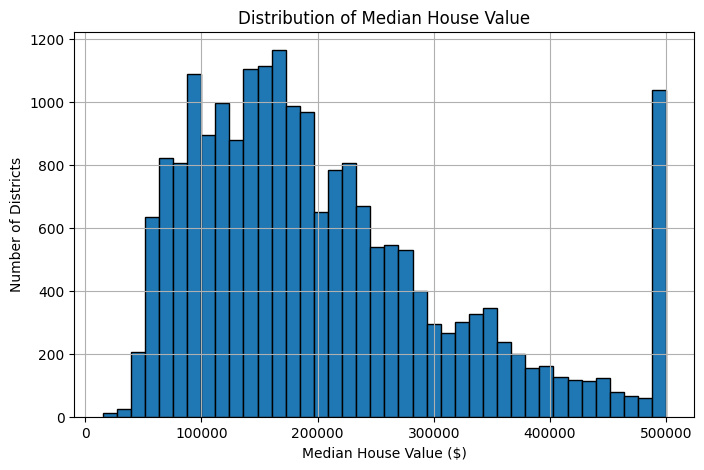

In [7]:
fig, ax = plt.subplots()

ax.hist(df["median_house_value"], bins=40, edgecolor="black")
ax.set_title("Distribution of Median House Value")
ax.set_xlabel("Median House Value ($)")
ax.set_ylabel("Number of Districts")

plt.show()


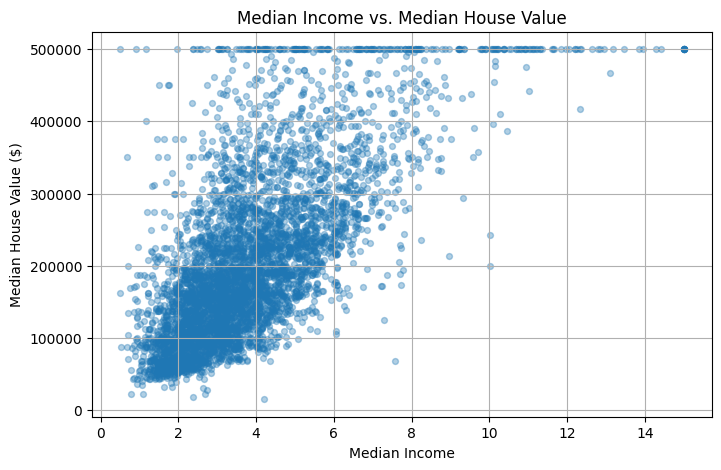

In [8]:
sample = df.sample(n=min(5000, len(df)), random_state=RANDOM_STATE)

fig, ax = plt.subplots()

scatter = ax.scatter(
    sample["median_income"],
    sample["median_house_value"],
    alpha=0.35,
    s=18,
)

ax.set_title("Median Income vs. Median House Value")
ax.set_xlabel("Median Income")
ax.set_ylabel("Median House Value ($)")

plt.show()


The scatter plot suggests that **median income** has a strong positive relationship with house value, although the relationship is not perfectly linear.


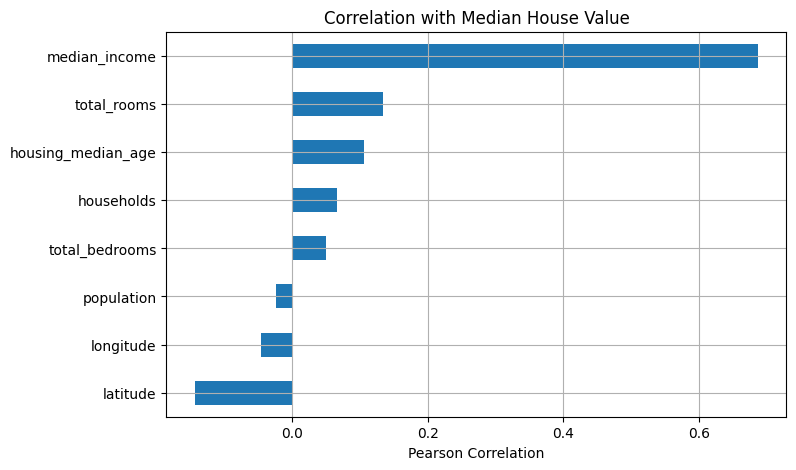

,correlation
latitude,-0.144160
longitude,-0.045967
population,-0.024650
total_bedrooms,0.049686
households,0.065843
housing_median_age,0.105623
total_rooms,0.134153
median_income,0.688075


In [9]:
numeric_corr = (
    df.select_dtypes(include=np.number)
      .corr(numeric_only=True)["median_house_value"]
      .drop("median_house_value")
      .sort_values()
)

fig, ax = plt.subplots(figsize=(8, 5))
numeric_corr.plot(kind="barh", ax=ax)

ax.set_title("Correlation with Median House Value")
ax.set_xlabel("Pearson Correlation")

plt.show()

numeric_corr.to_frame("correlation")


## 5. Prepare features and target

In [10]:
TARGET = "median_house_value"

X = df.drop(columns=TARGET)
y = df[TARGET]

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)


Numeric features:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income']

Categorical features:
['ocean_proximity']


### Train/test split

We keep **20% of the data for final testing**. The random state makes the split reproducible.


In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"Training set: {X_train.shape}")
print(f"Test set:     {X_test.shape}")


Training set: (16512, 9)
Test set:     (4128, 9)


## 6. Build the preprocessing pipeline

The preprocessing is handled automatically:

**Numerical features**
1. Fill missing values using the median
2. Standardize features

**Categorical features**
1. Fill missing values using the most frequent category
2. One-hot encode the categories

Using a `ColumnTransformer` and `Pipeline` prevents data leakage and keeps the workflow reusable.


In [12]:
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features),
])

preprocessor


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. `

## 7. Train and compare models

We compare three models:

- **Median Baseline** — predicts the median training target for every sample
- **Linear Regression** — simple and interpretable regression model
- **Random Forest** — captures non-linear patterns and feature interactions

No hyperparameter search is used, keeping the project compact.


In [13]:
models = {
    "Median Baseline": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DummyRegressor(strategy="median")),
    ]),

    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=120,
            max_depth=14,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}


In [14]:
def regression_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
    }


results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    metrics = regression_metrics(y_test, predictions)
    metrics["Model"] = name

    results.append(metrics)
    fitted_models[name] = model

results_df = (
    pd.DataFrame(results)
      .set_index("Model")
      .sort_values("RMSE")
)

results_df.round({
    "MAE": 0,
    "RMSE": 0,
    "R2": 3,
})


,MAE,RMSE,R2
Model,,,
Random Forest,32391.0,49656.0,0.812
Linear Regression,50670.0,70059.0,0.625
Median Baseline,87404.0,117312.0,-0.050


### Metric interpretation

- **MAE**: average absolute prediction error; lower is better.
- **RMSE**: penalizes larger errors more strongly; lower is better.
- **R²**: proportion of target variance explained by the model; closer to 1 is better.


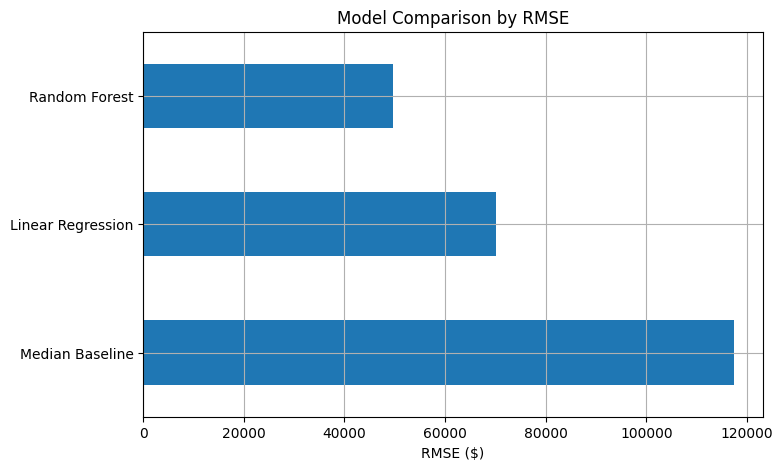

In [15]:
fig, ax = plt.subplots()

results_df["RMSE"].sort_values(ascending=False).plot(kind="barh", ax=ax)

ax.set_title("Model Comparison by RMSE")
ax.set_xlabel("RMSE ($)")
ax.set_ylabel("")

plt.show()


## 8. Evaluate the best model

In [16]:
best_model_name = results_df.index[0]
best_model = fitted_models[best_model_name]
best_predictions = best_model.predict(X_test)

print(f"Best model: {best_model_name}")
print(f"Test RMSE: ${results_df.loc[best_model_name, 'RMSE']:,.0f}")
print(f"Test MAE:  ${results_df.loc[best_model_name, 'MAE']:,.0f}")
print(f"Test R²:   {results_df.loc[best_model_name, 'R2']:.3f}")


Best model: Random Forest
Test RMSE: $49,656
Test MAE:  $32,391
Test R²:   0.812


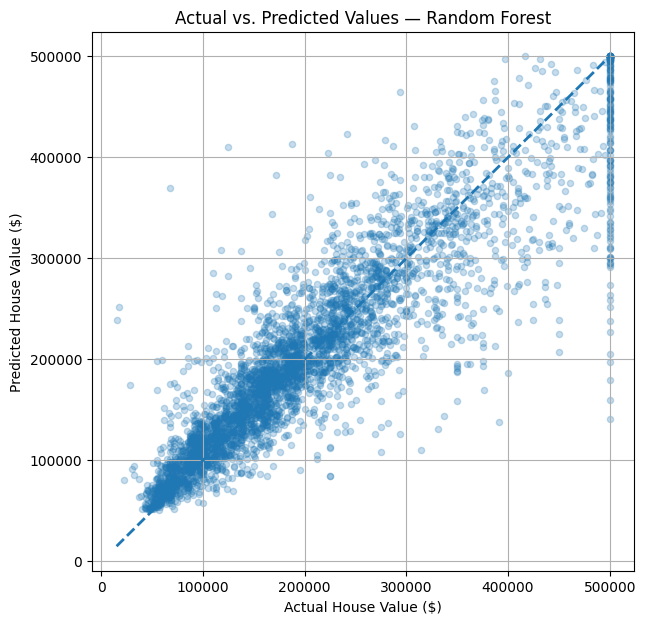

In [17]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.scatter(y_test, best_predictions, alpha=0.25, s=20)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())

ax.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--",
    linewidth=2,
)

ax.set_title(f"Actual vs. Predicted Values — {best_model_name}")
ax.set_xlabel("Actual House Value ($)")
ax.set_ylabel("Predicted House Value ($)")

plt.show()


## 9. Feature importance

Because the Random Forest is expected to be the strongest model here, we can inspect which transformed features contribute most to its predictions.


In [18]:
rf_pipeline = fitted_models["Random Forest"]

feature_names = (
    rf_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

feature_importances = (
    pd.Series(
        rf_pipeline.named_steps["model"].feature_importances_,
        index=feature_names,
        name="importance",
    )
    .sort_values(ascending=False)
)

top_features = feature_importances.head(12)
top_features.to_frame()


,importance
num__median_income,0.513805
cat__ocean_proximity_INLAND,0.150719
num__longitude,0.103597
num__latitude,0.098913
num__housing_median_age,0.047813
num__population,0.025577
num__total_bedrooms,0.018860
num__total_rooms,0.017094
num__households,0.013228
cat__ocean_proximity_NEAR OCEAN,0.006397


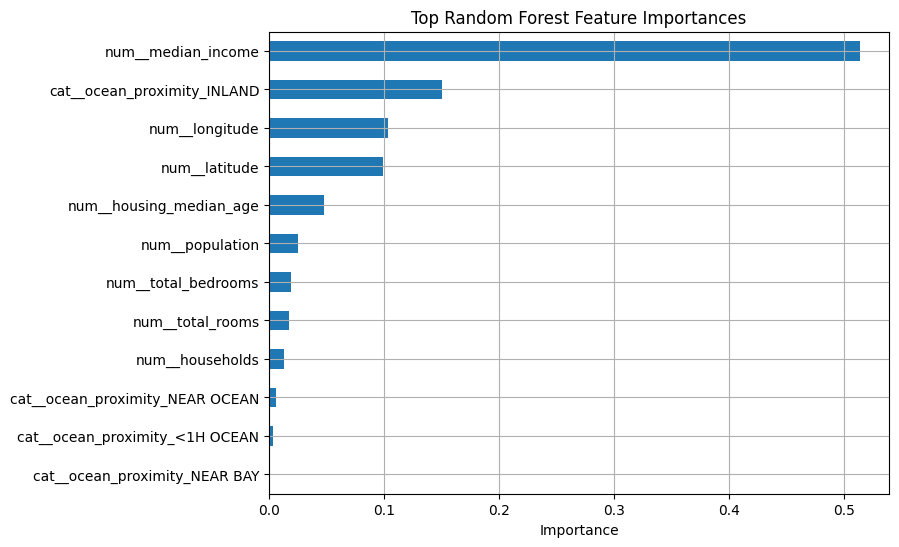

In [19]:
fig, ax = plt.subplots(figsize=(8, 6))

top_features.sort_values().plot(kind="barh", ax=ax)

ax.set_title("Top Random Forest Feature Importances")
ax.set_xlabel("Importance")
ax.set_ylabel("")

plt.show()
